In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('NYM_batting.csv')
# generate a random array of shape (3, 4)
random_array = np.random.rand(3, 4)
print("Random Array:")
print(random_array)
# print(random_array[0]) i make change 

Random Array:
[[0.02184499 0.12057762 0.32189758 0.3653367 ]
 [0.03736581 0.40193091 0.2067889  0.44504881]
 [0.11861027 0.61717251 0.99581016 0.91595426]]


In [18]:
# change example

In [19]:
batting = pd.read_csv('NYM_batting.csv')

In [20]:
pitching = pd.read_csv('NYM_pitching.csv')

In [21]:
batting.head()

,Rank,Year,Position,Name,Age,Games,Plate_Appearances,At_Bats,Runs,Hits,...,On_Base_Plus_Slugging_Percentage,On_Base_Plus_Slugging_Percentage_Plus,Total_Bases,Double_Plays_Grounded_Into,Times_Hit_By_Pitch,Sacrifice_Hits,Sacrifice_Flies,Intentional_Bases_on_Balls,Dominant_Hand,Switch_Hitter
0,1,2023,C,Francisco Álvarez,21,123,423,382,51,80,...,0.721,95,167,14,6,0,1,0,Right,No
1,2,2023,1B,Pete Alonso,28,154,658,568,92,123,...,0.821,122,286,17,21,0,4,6,Right,No
2,3,2023,2B,Jeff McNeil,31,156,648,585,75,158,...,0.711,96,221,5,18,3,3,0,Left,No
3,4,2023,SS,Francisco Lindor,29,160,687,602,108,153,...,0.806,120,283,8,12,0,7,1,Right,Yes
4,5,2023,3B,Brett Baty,23,108,389,353,41,75,...,0.598,65,114,8,2,1,1,0,Left,No


In [22]:
batting.info()

<class 'pandas.DataFrame'>
RangeIndex: 2728 entries, 0 to 2727
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rank                                   2728 non-null   int64  
 1   Year                                   2728 non-null   int64  
 2   Position                               2709 non-null   str    
 3   Name                                   2728 non-null   str    
 4   Age                                    2728 non-null   int64  
 5   Games                                  2728 non-null   int64  
 6   Plate_Appearances                      2728 non-null   int64  
 7   At_Bats                                2728 non-null   int64  
 8   Runs                                   2728 non-null   int64  
 9   Hits                                   2728 non-null   int64  
 10  Doubles                                2728 non-null   int64  
 11  Triples        

First, about the batting dataset. There are three categories of variables. First, the player demographics, which indicates the identifiers, demographic, defensive role, and physical traits of the player. Second, the opportunity and volume metrics, including how often the players play in the games, which implies how well the coach trusts the player, but this does not necessarily the player has a good performance. Third, offensive output and events, including different ways of scoring or different ways how players miss a chance of scoring intentionally for tactical playing. These values are raw counts without without standardizations. Fourth, rate and efficiency, which includes traditional metrics that evaluates how often the player gets a hit, how often a player avoids getting out (this is important for teamwork), metric that gives extra weight to extra-base hits that earns more points at a time, and composite metric combining the ability to get a base and the hits for power. 

              Rank         Year          Age        Games  Plate_Appearances  \
count  2728.000000  2728.000000  2728.000000  2728.000000        2728.000000   
mean     23.054985  1994.592009    28.060484    48.831012         136.707478   
std      13.676628    18.233108     4.317141    45.156003         187.243661   
min       1.000000  1962.000000    17.000000     0.000000           0.000000   
25%      11.750000  1979.000000    25.000000    12.000000           3.000000   
50%      22.500000  1996.000000    27.000000    33.000000          44.000000   
75%      34.000000  2010.000000    31.000000    74.000000         205.000000   
max      64.000000  2023.000000    48.000000   162.000000         765.000000   

           At_Bats         Runs         Hits      Doubles      Triples  ...  \
count  2728.000000  2728.000000  2728.000000  2728.000000  2728.000000  ...   
mean    121.663856    14.793988    30.409091     5.414589     0.656525  ...   
std     166.672170    23.514480    45.5505

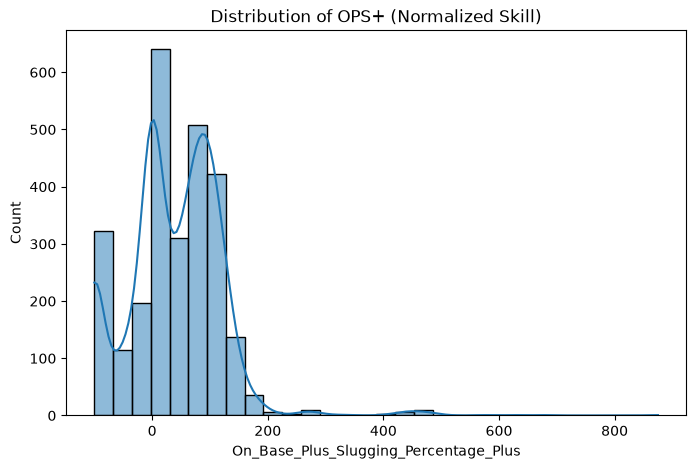

In [25]:
# Basic summary for numerical columns
print(batting.describe())

# Check distribution of OPS+ (league-normalized skill metric)
plt.figure(figsize=(8, 5))
sns.histplot(batting['On_Base_Plus_Slugging_Percentage_Plus'], kde=True, bins=30)
plt.title('Distribution of OPS+ (Normalized Skill)')
plt.show()

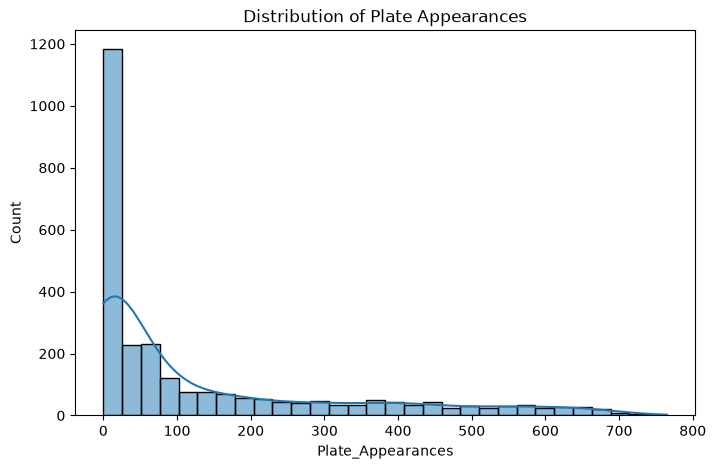

In [26]:
# Check distribution of Plate Appearances (PA) to see the skewness
plt.figure(figsize=(8, 5))
sns.histplot(batting['Plate_Appearances'], kde=True, bins=30)
plt.title('Distribution of Plate Appearances')
plt.show()

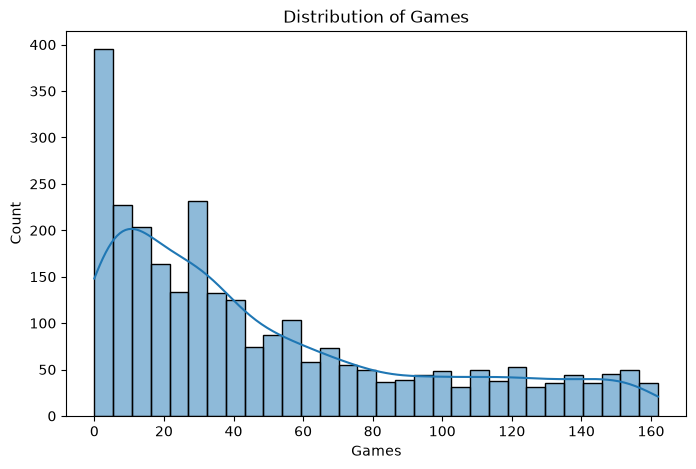

In [27]:
# Check distribution of Games to see the skewness
plt.figure(figsize=(8, 5))
sns.histplot(batting['Games'], kde=True, bins=30)
plt.title('Distribution of Games')
plt.show()

The distribution of Plate_Appearances and Games both show a heavy right skewness, which indicates that there are many players who play in a few games, but less players who play in many games. This means playing opportunities are really limited.

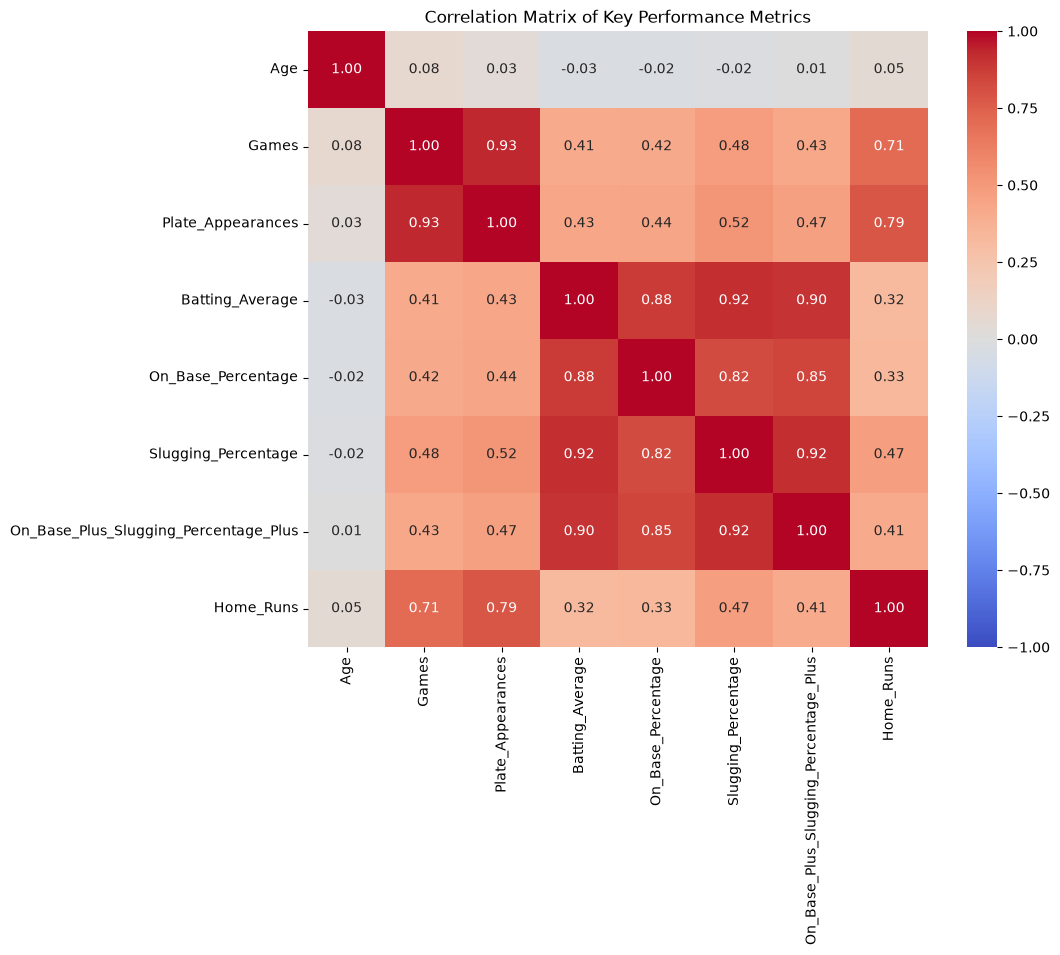

In [28]:
# Select key performance columns with standardized metrics for correlation analysis
performance_g1 = ['Age', 'Games', 'Plate_Appearances', 'Batting_Average', 
            'On_Base_Percentage', 'Slugging_Percentage', 'On_Base_Plus_Slugging_Percentage_Plus', 'Home_Runs']

# Calculate correlation matrix
corr_matrix = batting[performance_g1].corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Key Performance Metrics')
plt.show()

The correlation matrix and the heatmap indicates that there is a high correlation between Plate_Appearance and Games, between 